     Order_ID  Order_Date Customer_ID   Customer_Type                  Region  \
0  ORD-100001  2025-02-18   CUST-0297  Small Business  North Rhine-Westphalia   
1  ORD-100002  2026-05-22   CUST-0055        Consumer                   Hesse   
2  ORD-100003  2025-09-01   CUST-0297        Consumer       Baden-Württemberg   
3  ORD-100004  2025-09-14   CUST-0719        Consumer                 Bavaria   
4  ORD-100005  2025-05-11   CUST-0112        Consumer                 Bavaria   

        City Sales_Channel Product_ID     Product         Category  Quantity  \
0      Essen  Retail Store   PROD-103  Smartphone      Electronics         6   
1  Frankfurt        Online   PROD-110   Desk Lamp  Office Supplies         2   
2   Freiburg        Online   PROD-106        Desk        Furniture         1   
3  Nuremberg        Online   PROD-102     Monitor      Electronics         3   
4   Augsburg        Online   PROD-110   Desk Lamp  Office Supplies         3   

   Unit_Price  Discount    Sales

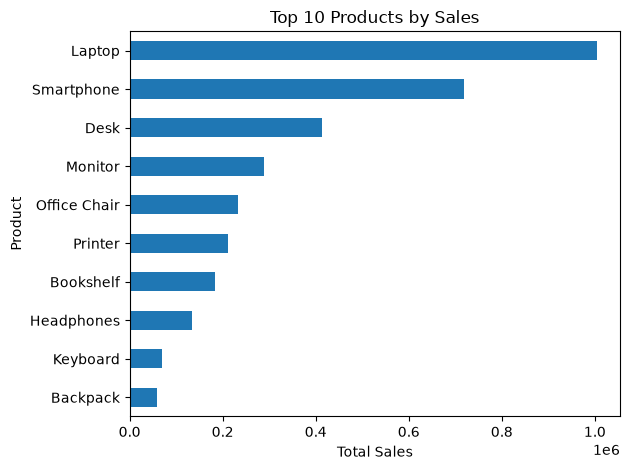

Dataset shape: (5000, 24)
Duplicate rows: 0
Total missing values: 0

Data types:
Order_ID                     str
Order_Date        datetime64[us]
Customer_ID                  str
Customer_Type                str
Region                       str
City                         str
Sales_Channel                str
Product_ID                   str
Product                      str
Category                     str
Quantity                   int64
Unit_Price               float64
Discount                 float64
Sales                    float64
Product_Cost             float64
Shipping_Cost            float64
Profit                   float64
Payment_Method               str
Order_Status                 str
Delivery_Days              int64
Year                       int32
Month                      int32
Month Name                   str
Profit Margin            float64
dtype: object

Numerical summary:
          Quantity   Unit_Price     Discount        Sales  Product_Cost  \
count  5000.000000

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/sales_dataset_raw.csv')
print(df.head())
print("Shape:",df.shape)

##understanding the dataset
df.info()
df.describe()

##check for missing values
missing_values = df.isnull().sum()
print("Missing Values:",missing_values)
print(missing_values[missing_values > 0])

## check for duplicates
duplicate_values = df.duplicated().sum()
print("Duplicate Values:",duplicate_values)

## remove duplicates
df.drop_duplicates(inplace=True)
print("Duplicates droped",df.duplicated().sum())
print(df.shape)

## convert the date
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
print(df['Order_Date'].dtypes)

## handles missing values
df['Discount'] = df['Discount'].fillna(0)  # missing discount is considered as no discount

df['City'] = df['City'].fillna('Unknown')

## confirm data is cleaned
print("Null Values:",df.isnull().sum())

print("Duplicates:",df.duplicated().sum())

# Extract time features
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Month Name"] = df["Order_Date"].dt.strftime("%b")

# Create a profit margin where revenue is positive
df["Profit Margin"] = np.where(
    df["Sales"] > 0,
    df["Profit"] / df["Sales"] * 100,
    np.nan
)

print(df.head())

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
average_sales = df["Sales"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Average Sales:", round(average_sales, 2))

product_sales = (
    df.groupby("Product")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print("Sales by Product:",product_sales)
print("Sales by Region:",region_sales)

## plotting chart 
product_sales.head(10).sort_values().plot(
    kind="barh",
    title="Top 10 Products by Sales"
)

plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# ## exporting cleaned data 
df.to_csv("../data/sales_cleaned.csv",index=False)

df.to_excel("../excel/sales_analysis.xlsx", index=False)

# Check dataset quality
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check numerical values
print("\nNumerical summary:")
print(df[[
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales",
    "Product_Cost",
    "Shipping_Cost",
    "Profit"
]].describe())